# Exercise 22 – k-means from scratch, and DBSCAN

**Week 4 · Descriptors and unsupervised learning**

**k-means** alternates two steps: assign every point to the nearest
centroid, then move each centroid to the mean of its points. **DBSCAN**
instead grows clusters from dense regions (at least `min_samples` neighbours
within `eps`) and labels isolated points as noise – it does not need the
number of clusters in advance.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.cluster import DBSCAN

rng = np.random.default_rng(0)


class KMeans:
    def __init__(self, n_clusters, max_iter=100, tol=1e-4, seed=42):
        self.n_clusters, self.max_iter, self.tol = n_clusters, max_iter, tol
        self.rng = np.random.default_rng(seed)

    def fit(self, X):
        self.centroids = X[self.rng.choice(len(X), self.n_clusters, replace=False)]
        self.n_iter = self.max_iter
        for i in range(self.max_iter):
            labels = self.predict(X)
            old = self.centroids.copy()
            self.centroids = np.array([X[labels == k].mean(axis=0) for k in range(self.n_clusters)])
            if np.all(np.linalg.norm(self.centroids - old, axis=1) < self.tol):
                self.n_iter = i + 1
                break
        return self

    def predict(self, X):
        return np.argmin(np.linalg.norm(X[:, None] - self.centroids, axis=2), axis=1)

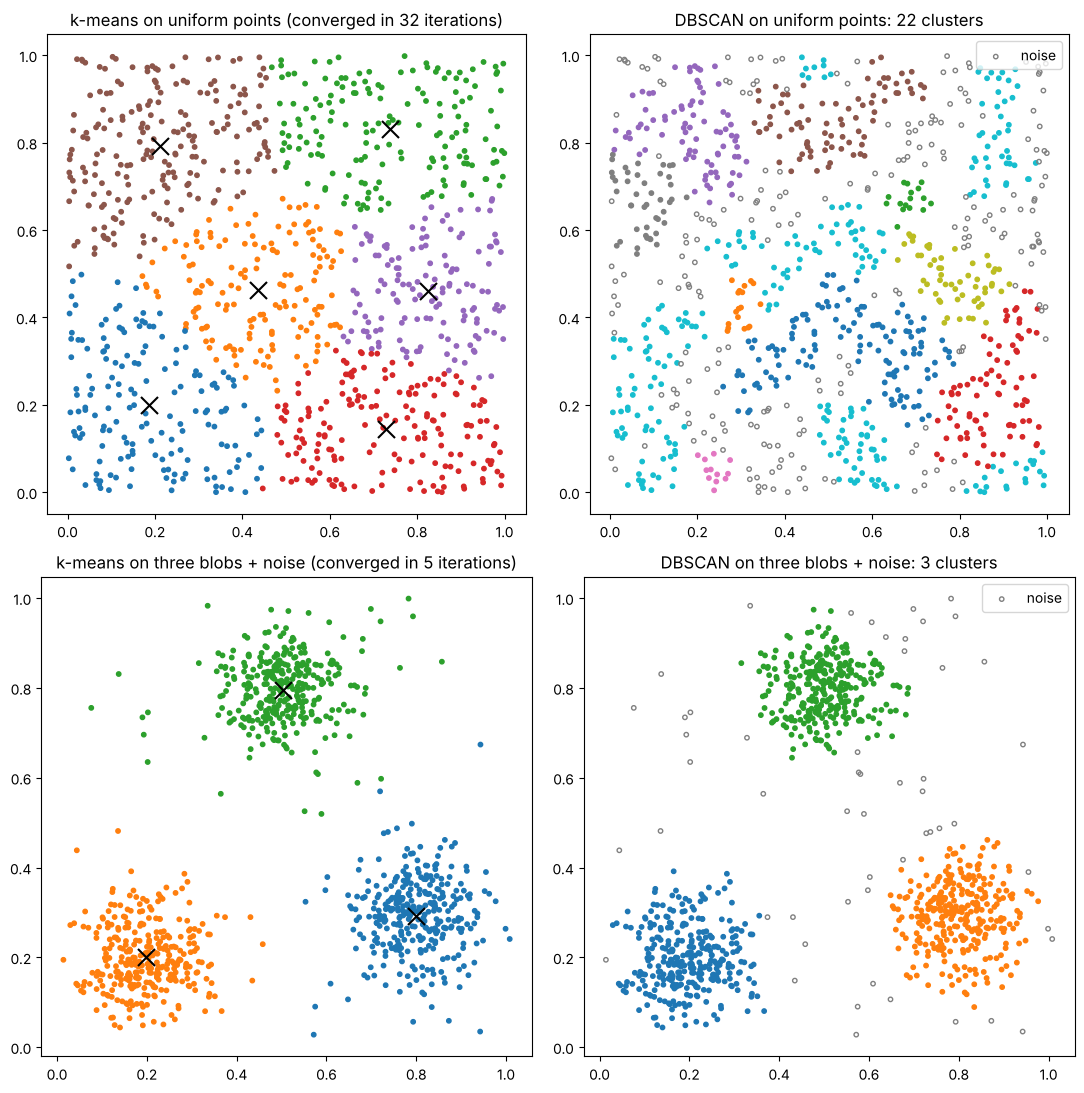

In [2]:
uniform = rng.random((1000, 2))
centres = np.array([[0.2, 0.2], [0.8, 0.3], [0.5, 0.8]])
blobs = np.vstack([c + 0.07 * rng.normal(size=(300, 2)) for c in centres] + [rng.random((60, 2))])

fig, axes = plt.subplots(2, 2, figsize=(11, 11))
for row, (X, name) in zip(axes, [(uniform, "uniform points"), (blobs, "three blobs + noise")]):
    km = KMeans(n_clusters=6 if X is uniform else 3).fit(X)
    row[0].scatter(*X.T, c=km.predict(X), cmap="tab10", vmax=9, s=10)
    row[0].scatter(*km.centroids.T, marker="x", s=150, color="black")
    row[0].set(title=f"k-means on {name} (converged in {km.n_iter} iterations)", aspect="equal")

    labels = DBSCAN(eps=0.05, min_samples=10).fit_predict(X)
    n_found = len(set(labels)) - (-1 in labels)
    noise = labels == -1
    row[1].scatter(*X[~noise].T, c=labels[~noise], cmap="tab10", vmax=9, s=10)
    row[1].scatter(*X[noise].T, facecolor="none", edgecolor="gray", s=10, label="noise")
    row[1].set(title=f"DBSCAN on {name}: {n_found} clusters", aspect="equal")
    row[1].legend(loc="upper right")
fig.tight_layout()
plt.show()

k-means always partitions the data into $k$ groups – even uniformly spread
points get chopped into regions. DBSCAN finds the three blobs and marks the
scattered background as noise, but on uniform data the result depends
strongly on `eps` and `min_samples`.